# Credit Score Dataset — Complete EDA & Data Cleaning

Complete notebook for `CreditScore.csv`: data overview, data quality, missing values, duplicates, descriptive statistics, graphs, bivariate analysis, correlation, invalid values, outliers, cleaning, and before/after comparison.


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")


## 2. Load Dataset

In [2]:
df = pd.read_csv("CreditScore.csv", low_memory=False)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (150000, 13)


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Gender,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766,f,45,2,0.803,"9,120.000",13,0,6,0,2.000
1,2,0,0.957,m,40,0,0.122,"2,600.000",4,0,0,0,1.000
2,3,0,0.658,f,38,1,0.085,"3,042.000",2,1,0,0,0.000
3,4,0,0.234,m,30,0,0.036,"3,300.000",5,0,0,0,0.000
4,5,0,0.907,f,49,1,0.025,"63,588.000",7,0,1,0,0.000


## 3. Dataset Information

In [3]:
print(df.info())
overview = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null": df.notna().sum(),
    "Missing": df.isna().sum(),
    "Missing %": (df.isna().mean()*100).round(2),
    "Unique": df.nunique(dropna=True)
})
display(overview)


<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 13 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Id                                    150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   Gender                                307 non-null     str    
 4   Age                                   150000 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 6   DebtRatio                             150000 non-null  float64
 7   MonthlyIncome                         120269 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 9   NumberOfTimes90DaysLate               150000 non-null  int64  
 10  NumberRealEstateLoansOrLines          150000 non-null  int64  
 11  NumberOfTim

,Data Type,Non-Null,Missing,Missing %,Unique
Id,int64,150000,0,0.000,150000
SeriousDlqin2yrs,int64,150000,0,0.000,2
RevolvingUtilizationOfUnsecuredLines,float64,150000,0,0.000,125728
Gender,str,307,149693,99.800,2
Age,int64,150000,0,0.000,86
NumberOfTime30-59DaysPastDueNotWorse,int64,150000,0,0.000,16
DebtRatio,float64,150000,0,0.000,114194
MonthlyIncome,float64,120269,29731,19.820,13594
NumberOfOpenCreditLinesAndLoans,int64,150000,0,0.000,58
NumberOfTimes90DaysLate,int64,150000,0,0.000,19


## 4. Variable Overview

`Id` is the customer identifier. `SeriousDlqin2yrs` is the binary target. The remaining fields describe utilization, demographics, income, debt, credit/loan counts, delinquency history, and dependents.


## 5. Missing Values

In [4]:
missing = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean()*100).round(2)
}).sort_values("Missing Values", ascending=False)
display(missing)


,Missing Values,Missing Percentage
Gender,149693,99.800
MonthlyIncome,29731,19.820
NumberOfDependents,3924,2.620
Id,0,0.000
SeriousDlqin2yrs,0,0.000
Age,0,0.000
RevolvingUtilizationOfUnsecuredLines,0,0.000
DebtRatio,0,0.000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000
NumberOfOpenCreditLinesAndLoans,0,0.000


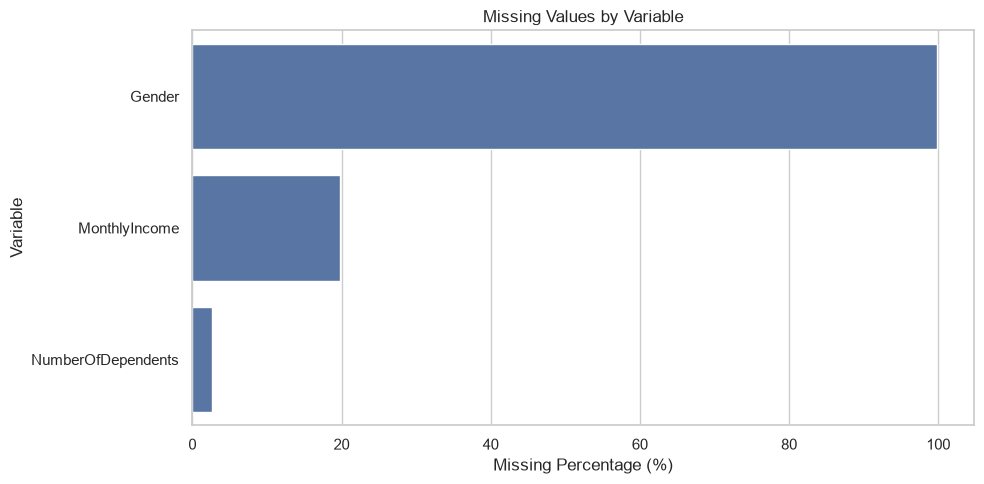

In [5]:
m = missing[missing["Missing Values"] > 0]
plt.figure(figsize=(10,5))
sns.barplot(x=m["Missing Percentage"].values, y=m.index)
plt.title("Missing Values by Variable")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


## 6. Duplicate Records

In [6]:
print("Duplicate complete rows:", df.duplicated().sum())
print("Duplicate Id values:", df["Id"].duplicated().sum())


Duplicate complete rows: 0
Duplicate Id values: 0


## 7. Target Variable Analysis

In [7]:
target = df["SeriousDlqin2yrs"].value_counts().sort_index()
display(pd.DataFrame({
    "Count": target,
    "Percentage": (target/len(df)*100).round(2)
}))


,Count,Percentage
SeriousDlqin2yrs,,
0,139974,93.320
1,10026,6.680


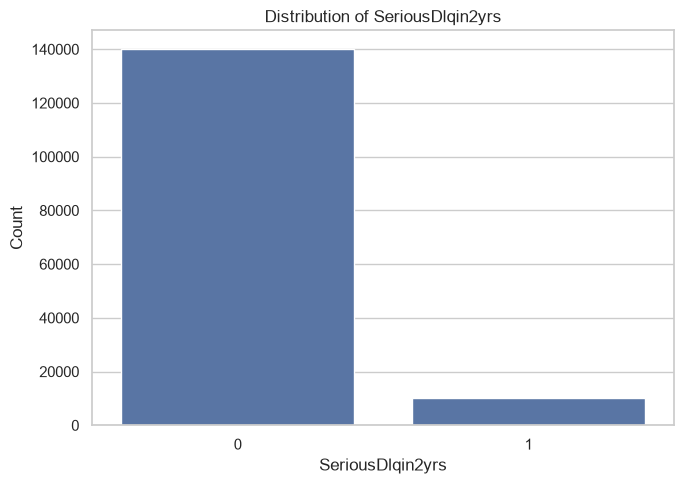

In [8]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="SeriousDlqin2yrs")
plt.title("Distribution of SeriousDlqin2yrs")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


## 8. Gender Investigation

In [9]:
print("Gender dtype:", df["Gender"].dtype)
display(df["Gender"].value_counts(dropna=False))
print("Unique values:", df["Gender"].unique())


Gender dtype: str


Gender
NaN    149693
m         223
f          84
Name: count, dtype: int64

Unique values: <ArrowStringArray>
['f', 'm', nan]
Length: 3, dtype: str


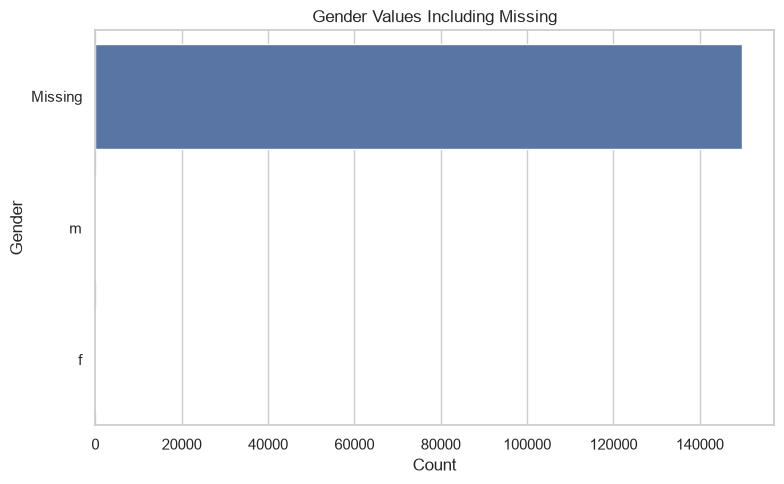

In [10]:
g=df["Gender"].fillna("Missing").astype(str).value_counts()
plt.figure(figsize=(8,5))
sns.barplot(x=g.values,y=g.index)
plt.title("Gender Values Including Missing")
plt.xlabel("Count")
plt.ylabel("Gender")
plt.tight_layout()
plt.show()


## 9. Descriptive Statistics

In [11]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,"150,000.000",NaN,NaN,NaN,"75,000.500","43,301.415",1.000,"37,500.750","75,000.500","112,500.250","150,000.000"
SeriousDlqin2yrs,"150,000.000",NaN,NaN,NaN,0.067,0.250,0.000,0.000,0.000,0.000,1.000
RevolvingUtilizationOfUnsecuredLines,"150,000.000",NaN,NaN,NaN,6.048,249.755,0.000,0.030,0.154,0.559,"50,708.000"
Gender,307,2,m,223,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"150,000.000",NaN,NaN,NaN,52.295,14.772,0.000,41.000,52.000,63.000,109.000
NumberOfTime30-59DaysPastDueNotWorse,"150,000.000",NaN,NaN,NaN,0.421,4.193,0.000,0.000,0.000,0.000,98.000
DebtRatio,"150,000.000",NaN,NaN,NaN,353.005,"2,037.819",0.000,0.175,0.367,0.868,"329,664.000"
MonthlyIncome,"120,269.000",NaN,NaN,NaN,"6,670.221","14,384.674",0.000,"3,400.000","5,400.000","8,249.000","3,008,750.000"
NumberOfOpenCreditLinesAndLoans,"150,000.000",NaN,NaN,NaN,8.453,5.146,0.000,5.000,8.000,11.000,58.000
NumberOfTimes90DaysLate,"150,000.000",NaN,NaN,NaN,0.266,4.169,0.000,0.000,0.000,0.000,98.000


## 10. Numerical Distributions and Boxplots

In [12]:
numeric_cols=df.select_dtypes(include=np.number).columns.tolist()
numeric_predictors=[c for c in numeric_cols if c not in ["Id","SeriousDlqin2yrs"]]
print(numeric_predictors)


['RevolvingUtilizationOfUnsecuredLines', 'Age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


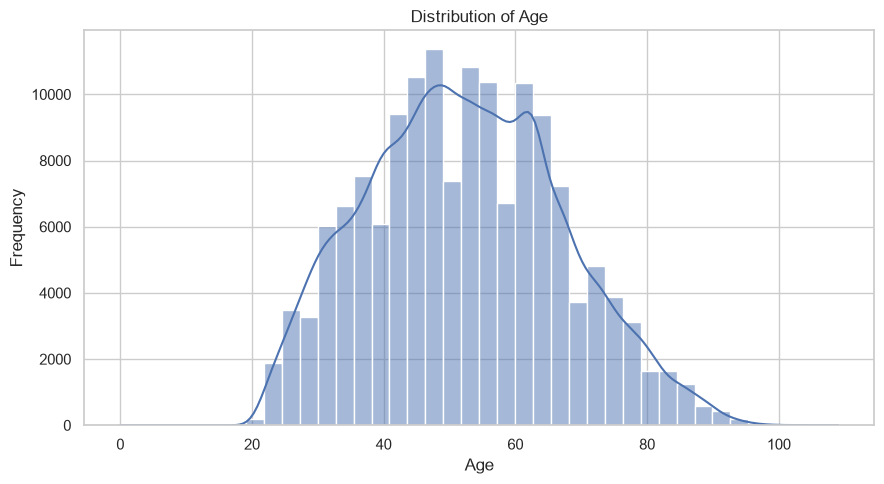

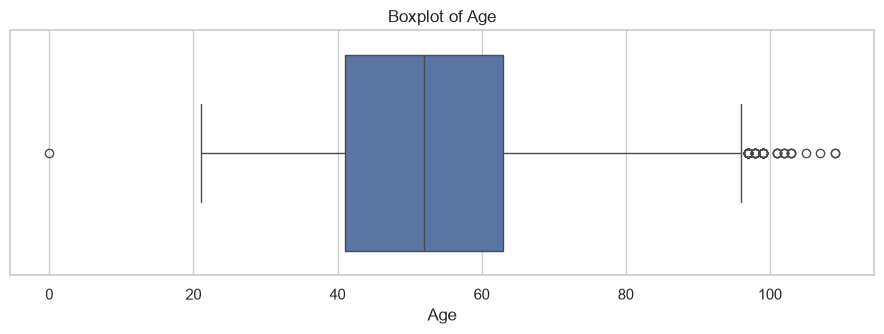

In [13]:
plt.figure(figsize=(9,5))
sns.histplot(df["Age"].dropna(),bins=40,kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["Age"])
plt.title("Boxplot of Age")
plt.xlabel("Age")
plt.tight_layout()
plt.show()


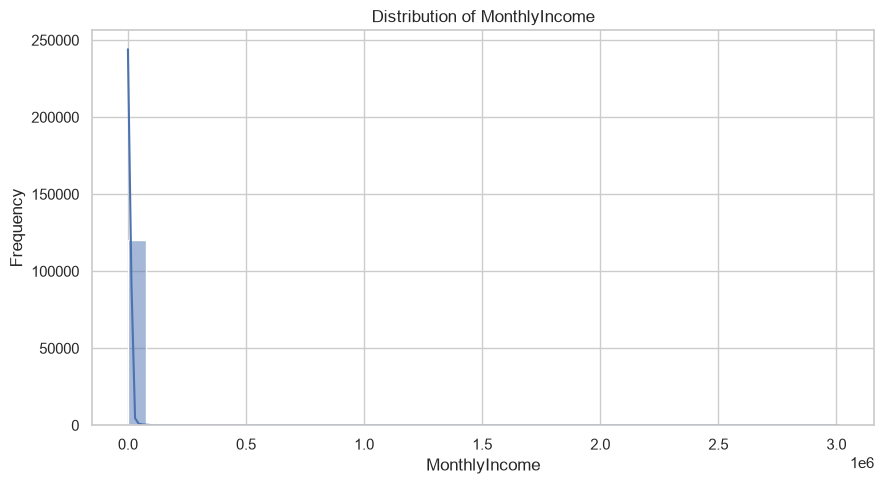

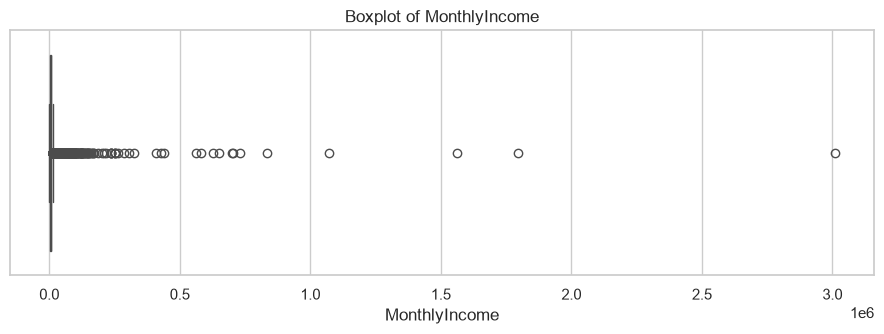

In [14]:
plt.figure(figsize=(9,5))
sns.histplot(df["MonthlyIncome"].dropna(),bins=40,kde=True)
plt.title("Distribution of MonthlyIncome")
plt.xlabel("MonthlyIncome")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["MonthlyIncome"])
plt.title("Boxplot of MonthlyIncome")
plt.xlabel("MonthlyIncome")
plt.tight_layout()
plt.show()


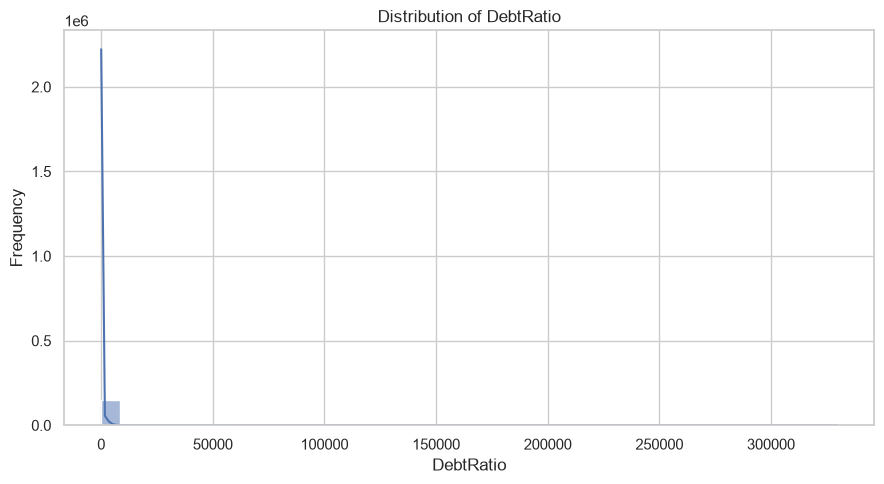

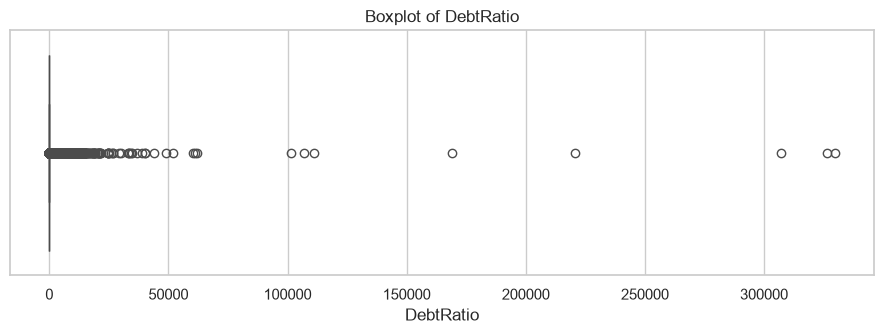

In [15]:
plt.figure(figsize=(9,5))
sns.histplot(df["DebtRatio"].dropna(),bins=40,kde=True)
plt.title("Distribution of DebtRatio")
plt.xlabel("DebtRatio")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["DebtRatio"])
plt.title("Boxplot of DebtRatio")
plt.xlabel("DebtRatio")
plt.tight_layout()
plt.show()


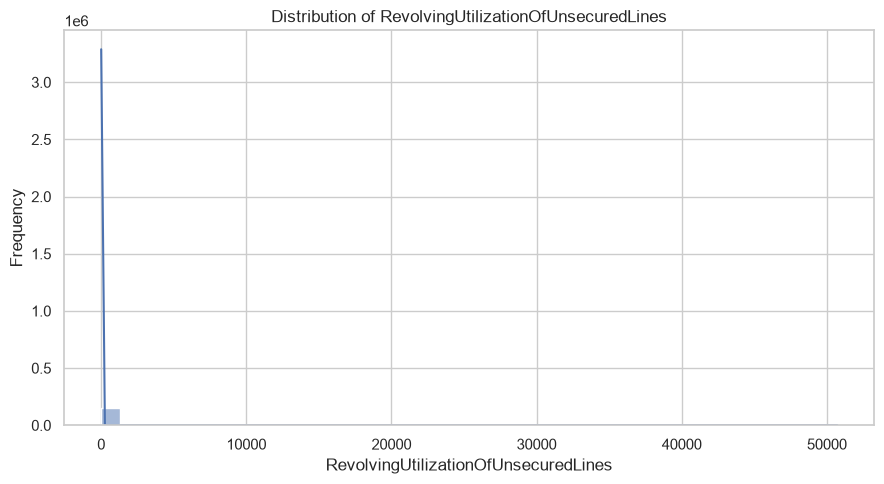

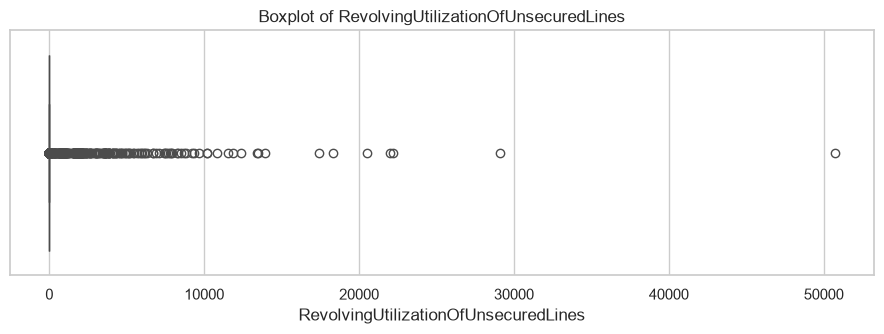

In [16]:
plt.figure(figsize=(9,5))
sns.histplot(df["RevolvingUtilizationOfUnsecuredLines"].dropna(),bins=40,kde=True)
plt.title("Distribution of RevolvingUtilizationOfUnsecuredLines")
plt.xlabel("RevolvingUtilizationOfUnsecuredLines")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["RevolvingUtilizationOfUnsecuredLines"])
plt.title("Boxplot of RevolvingUtilizationOfUnsecuredLines")
plt.xlabel("RevolvingUtilizationOfUnsecuredLines")
plt.tight_layout()
plt.show()


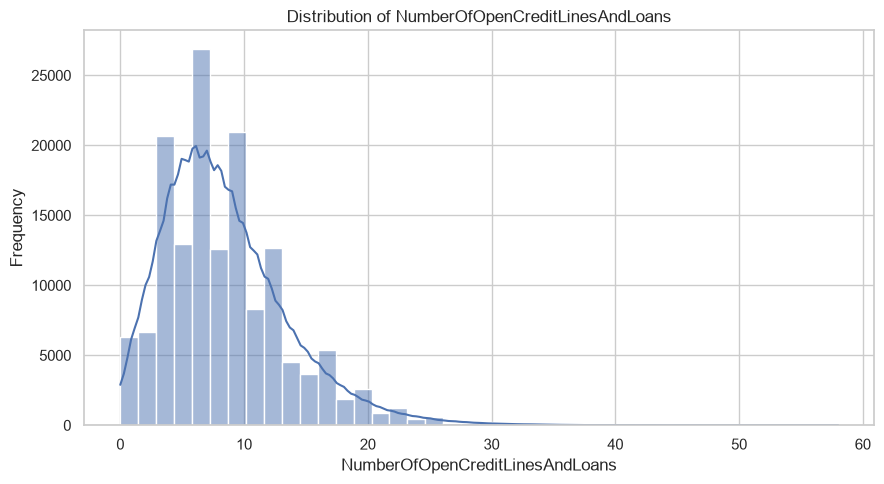

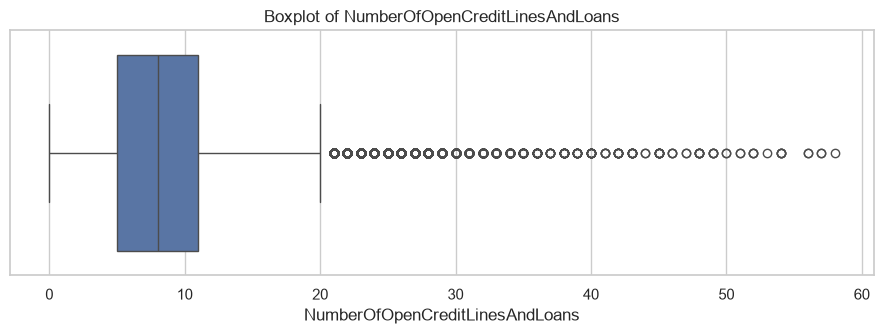

In [17]:
plt.figure(figsize=(9,5))
sns.histplot(df["NumberOfOpenCreditLinesAndLoans"].dropna(),bins=40,kde=True)
plt.title("Distribution of NumberOfOpenCreditLinesAndLoans")
plt.xlabel("NumberOfOpenCreditLinesAndLoans")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["NumberOfOpenCreditLinesAndLoans"])
plt.title("Boxplot of NumberOfOpenCreditLinesAndLoans")
plt.xlabel("NumberOfOpenCreditLinesAndLoans")
plt.tight_layout()
plt.show()


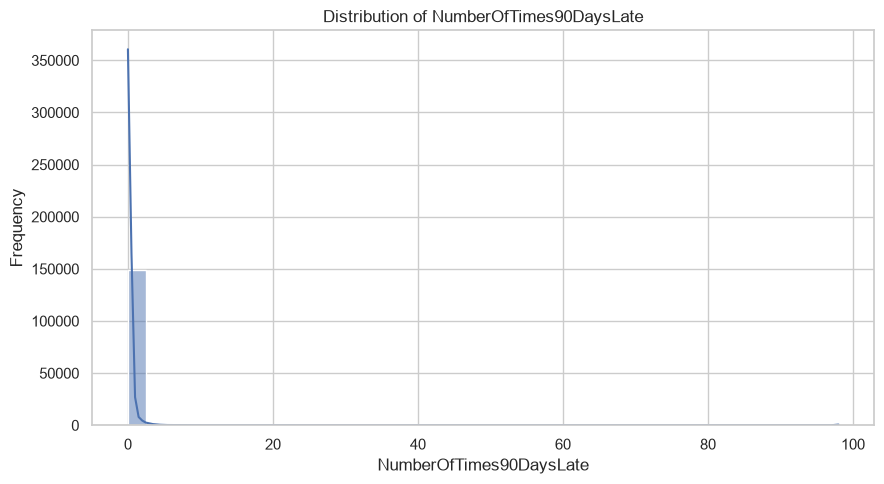

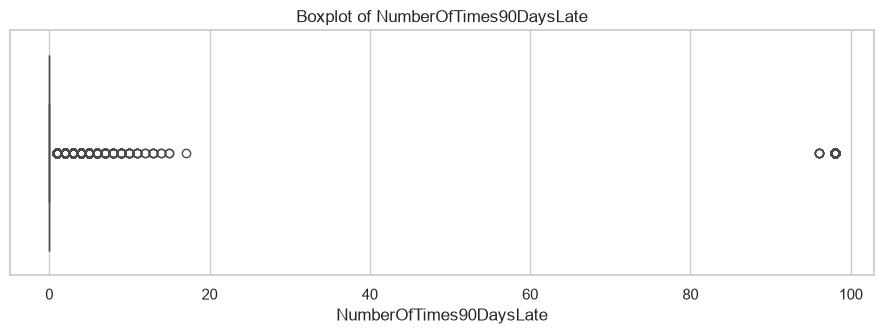

In [18]:
plt.figure(figsize=(9,5))
sns.histplot(df["NumberOfTimes90DaysLate"].dropna(),bins=40,kde=True)
plt.title("Distribution of NumberOfTimes90DaysLate")
plt.xlabel("NumberOfTimes90DaysLate")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["NumberOfTimes90DaysLate"])
plt.title("Boxplot of NumberOfTimes90DaysLate")
plt.xlabel("NumberOfTimes90DaysLate")
plt.tight_layout()
plt.show()


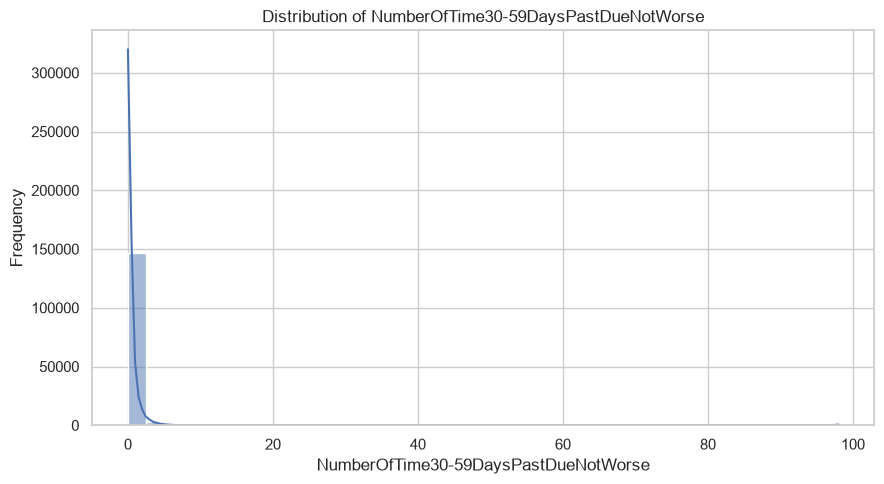

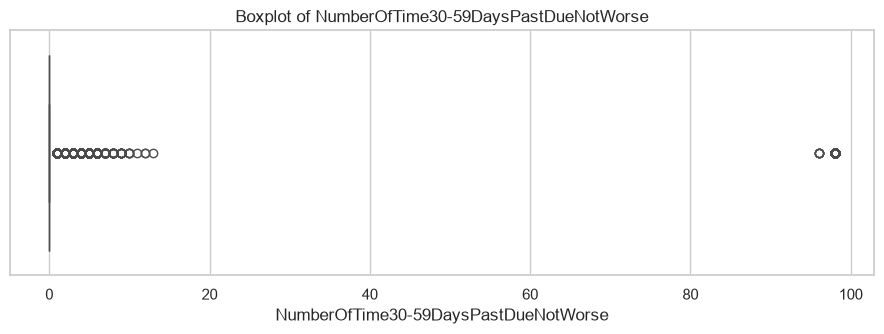

In [19]:
plt.figure(figsize=(9,5))
sns.histplot(df["NumberOfTime30-59DaysPastDueNotWorse"].dropna(),bins=40,kde=True)
plt.title("Distribution of NumberOfTime30-59DaysPastDueNotWorse")
plt.xlabel("NumberOfTime30-59DaysPastDueNotWorse")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["NumberOfTime30-59DaysPastDueNotWorse"])
plt.title("Boxplot of NumberOfTime30-59DaysPastDueNotWorse")
plt.xlabel("NumberOfTime30-59DaysPastDueNotWorse")
plt.tight_layout()
plt.show()


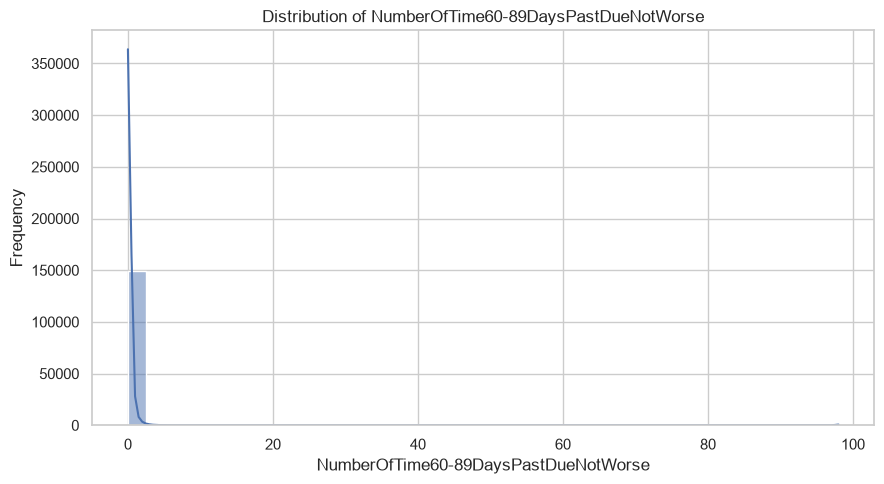

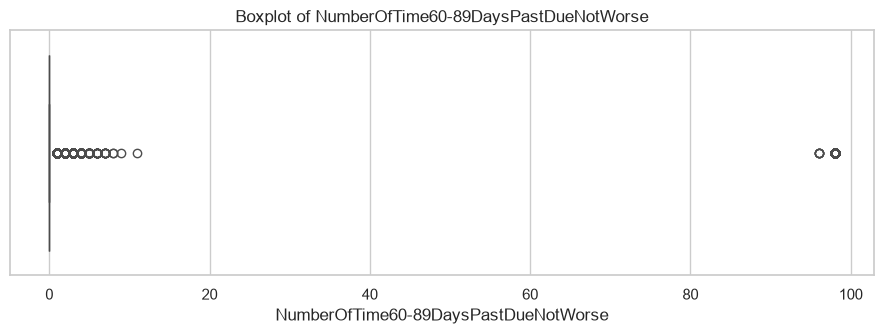

In [20]:
plt.figure(figsize=(9,5))
sns.histplot(df["NumberOfTime60-89DaysPastDueNotWorse"].dropna(),bins=40,kde=True)
plt.title("Distribution of NumberOfTime60-89DaysPastDueNotWorse")
plt.xlabel("NumberOfTime60-89DaysPastDueNotWorse")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["NumberOfTime60-89DaysPastDueNotWorse"])
plt.title("Boxplot of NumberOfTime60-89DaysPastDueNotWorse")
plt.xlabel("NumberOfTime60-89DaysPastDueNotWorse")
plt.tight_layout()
plt.show()


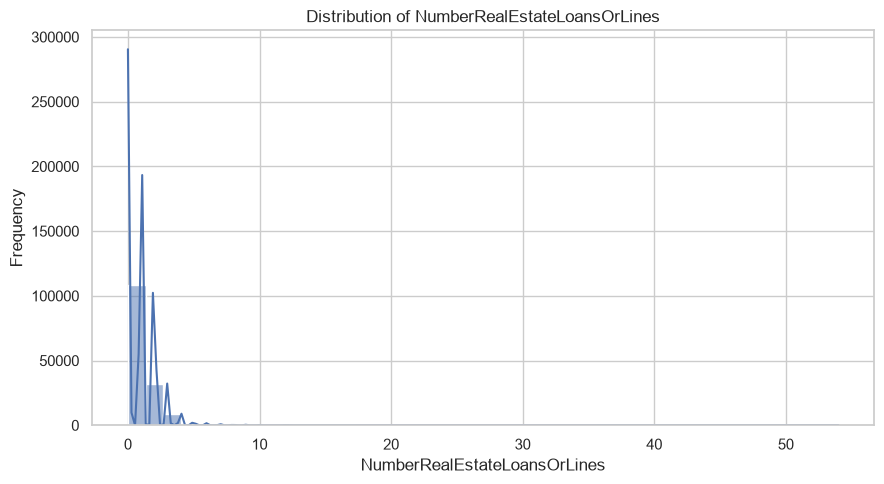

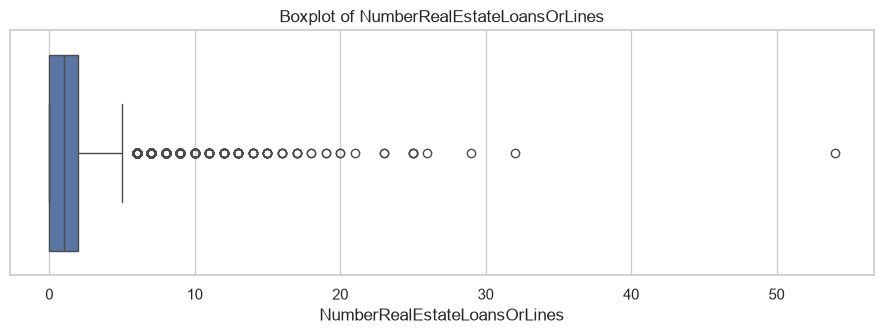

In [21]:
plt.figure(figsize=(9,5))
sns.histplot(df["NumberRealEstateLoansOrLines"].dropna(),bins=40,kde=True)
plt.title("Distribution of NumberRealEstateLoansOrLines")
plt.xlabel("NumberRealEstateLoansOrLines")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["NumberRealEstateLoansOrLines"])
plt.title("Boxplot of NumberRealEstateLoansOrLines")
plt.xlabel("NumberRealEstateLoansOrLines")
plt.tight_layout()
plt.show()


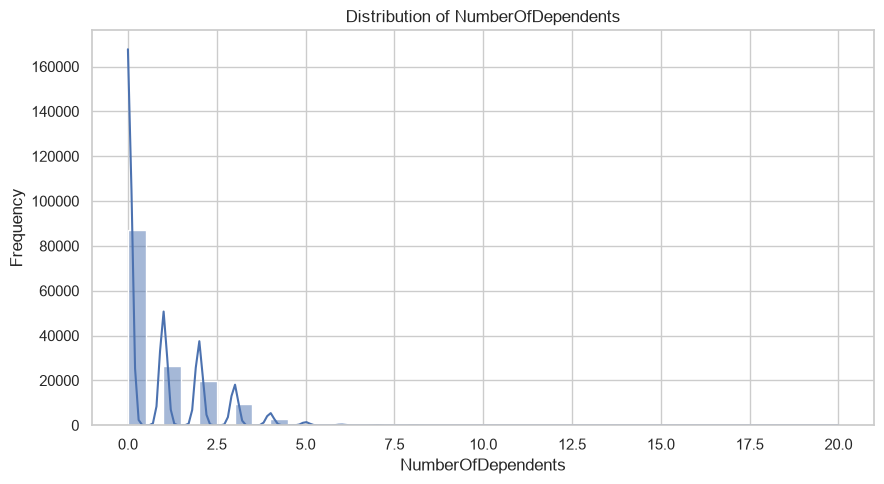

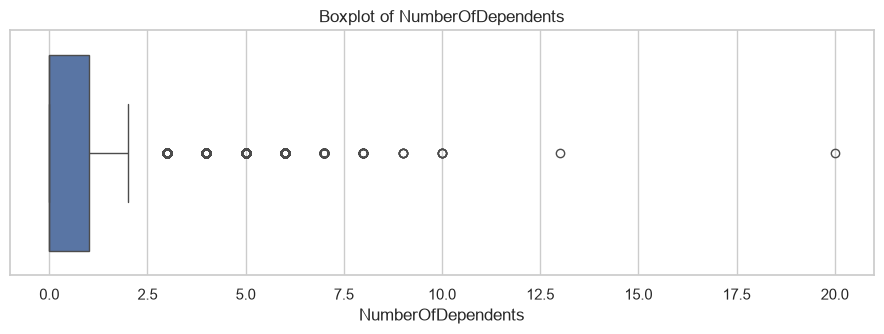

In [22]:
plt.figure(figsize=(9,5))
sns.histplot(df["NumberOfDependents"].dropna(),bins=40,kde=True)
plt.title("Distribution of NumberOfDependents")
plt.xlabel("NumberOfDependents")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["NumberOfDependents"])
plt.title("Boxplot of NumberOfDependents")
plt.xlabel("NumberOfDependents")
plt.tight_layout()
plt.show()


## 11. Bivariate Analysis — Important Variables vs Target

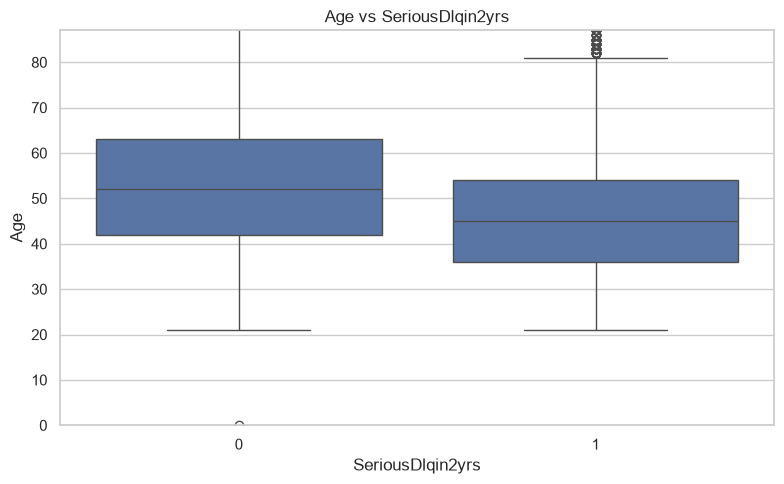

In [23]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="SeriousDlqin2yrs",y="Age")
plt.title("Age vs SeriousDlqin2yrs")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("Age")
upper=df["Age"].quantile(.99)
if np.isfinite(upper) and upper>0:
    plt.ylim(0,upper)
plt.tight_layout()
plt.show()


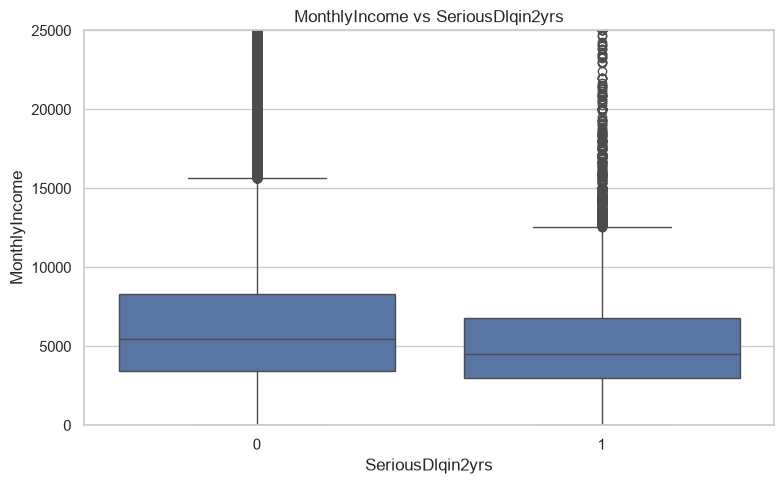

In [24]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="SeriousDlqin2yrs",y="MonthlyIncome")
plt.title("MonthlyIncome vs SeriousDlqin2yrs")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("MonthlyIncome")
upper=df["MonthlyIncome"].quantile(.99)
if np.isfinite(upper) and upper>0:
    plt.ylim(0,upper)
plt.tight_layout()
plt.show()


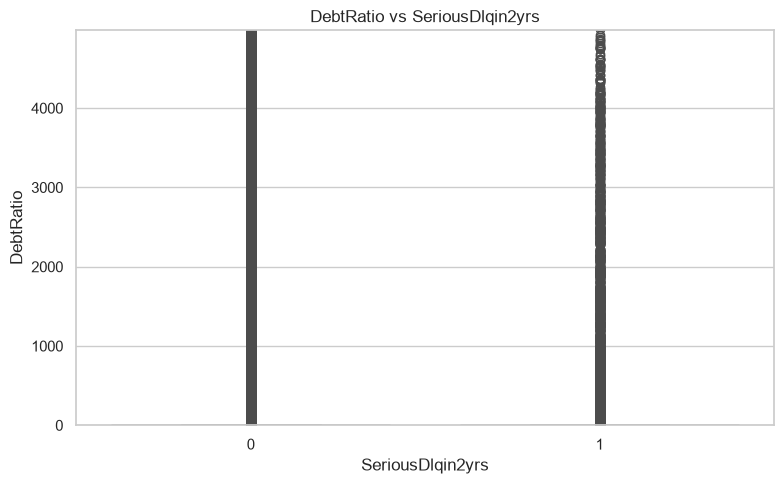

In [25]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="SeriousDlqin2yrs",y="DebtRatio")
plt.title("DebtRatio vs SeriousDlqin2yrs")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("DebtRatio")
upper=df["DebtRatio"].quantile(.99)
if np.isfinite(upper) and upper>0:
    plt.ylim(0,upper)
plt.tight_layout()
plt.show()


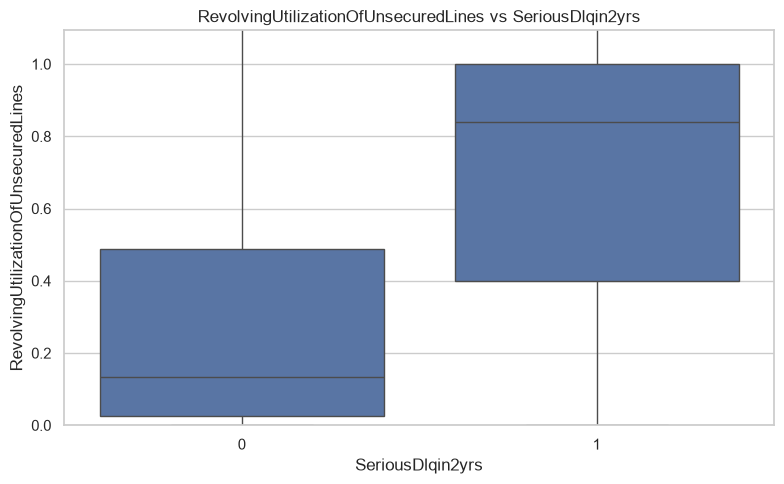

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="SeriousDlqin2yrs",y="RevolvingUtilizationOfUnsecuredLines")
plt.title("RevolvingUtilizationOfUnsecuredLines vs SeriousDlqin2yrs")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("RevolvingUtilizationOfUnsecuredLines")
upper=df["RevolvingUtilizationOfUnsecuredLines"].quantile(.99)
if np.isfinite(upper) and upper>0:
    plt.ylim(0,upper)
plt.tight_layout()
plt.show()


## 12. Target Rate by Age Group

In [27]:
bins=[0,25,35,45,55,65,75,np.inf]
labels=["<=25","26-35","36-45","46-55","56-65","66-75","76+"]
tmp=df.copy()
tmp["AgeGroup"]=pd.cut(tmp["Age"],bins=bins,labels=labels,include_lowest=True)
age_rate=tmp.groupby("AgeGroup",observed=False)["SeriousDlqin2yrs"].mean().mul(100).reset_index(name="Delinquency Rate (%)")
display(age_rate)


,AgeGroup,Delinquency Rate (%)
0,<=25,11.162
1,26-35,11.123
2,36-45,8.813
3,46-55,7.593
4,56-65,4.583
5,66-75,2.615
6,76+,2.044


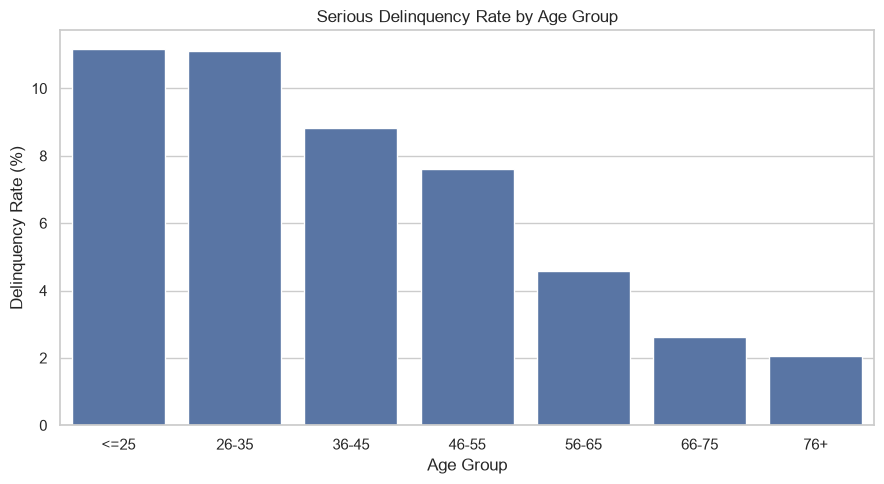

In [28]:
plt.figure(figsize=(9,5))
sns.barplot(data=age_rate,x="AgeGroup",y="Delinquency Rate (%)")
plt.title("Serious Delinquency Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Delinquency Rate (%)")
plt.tight_layout()
plt.show()


## 13. Delinquency History vs Target

In [29]:
delinq_cols=[
"NumberOfTime30-59DaysPastDueNotWorse",
"NumberOfTimes90DaysLate",
"NumberOfTime60-89DaysPastDueNotWorse"]
for col in delinq_cols:
    print("\n",col)
    s=df.groupby(col)["SeriousDlqin2yrs"].agg(["count","mean"]).reset_index()
    s["mean"]=s["mean"]*100
    display(s.head(20))



 NumberOfTime30-59DaysPastDueNotWorse


,NumberOfTime30-59DaysPastDueNotWorse,count,mean
0,0,126018,4.000
1,1,16033,15.025
2,2,4598,26.512
3,3,1754,35.234
4,4,747,42.570
5,5,342,45.029
6,6,140,52.857
7,7,54,51.852
8,8,25,32.000
9,9,12,33.333



 NumberOfTimes90DaysLate


,NumberOfTimes90DaysLate,count,mean
0,0,141662,4.627
1,1,5243,33.664
2,2,1555,49.904
3,3,667,57.721
4,4,291,67.010
5,5,131,63.359
6,6,80,60.000
7,7,38,81.579
8,8,21,71.429
9,9,19,73.684



 NumberOfTime60-89DaysPastDueNotWorse


,NumberOfTime60-89DaysPastDueNotWorse,count,mean
0,0,142396,5.096
1,1,5731,31.007
2,2,1118,50.179
3,3,318,56.604
4,4,105,61.905
5,5,34,61.765
6,6,16,75.000
7,7,9,55.556
8,8,2,50.000
9,9,1,0.000


## 14. Correlation Matrix

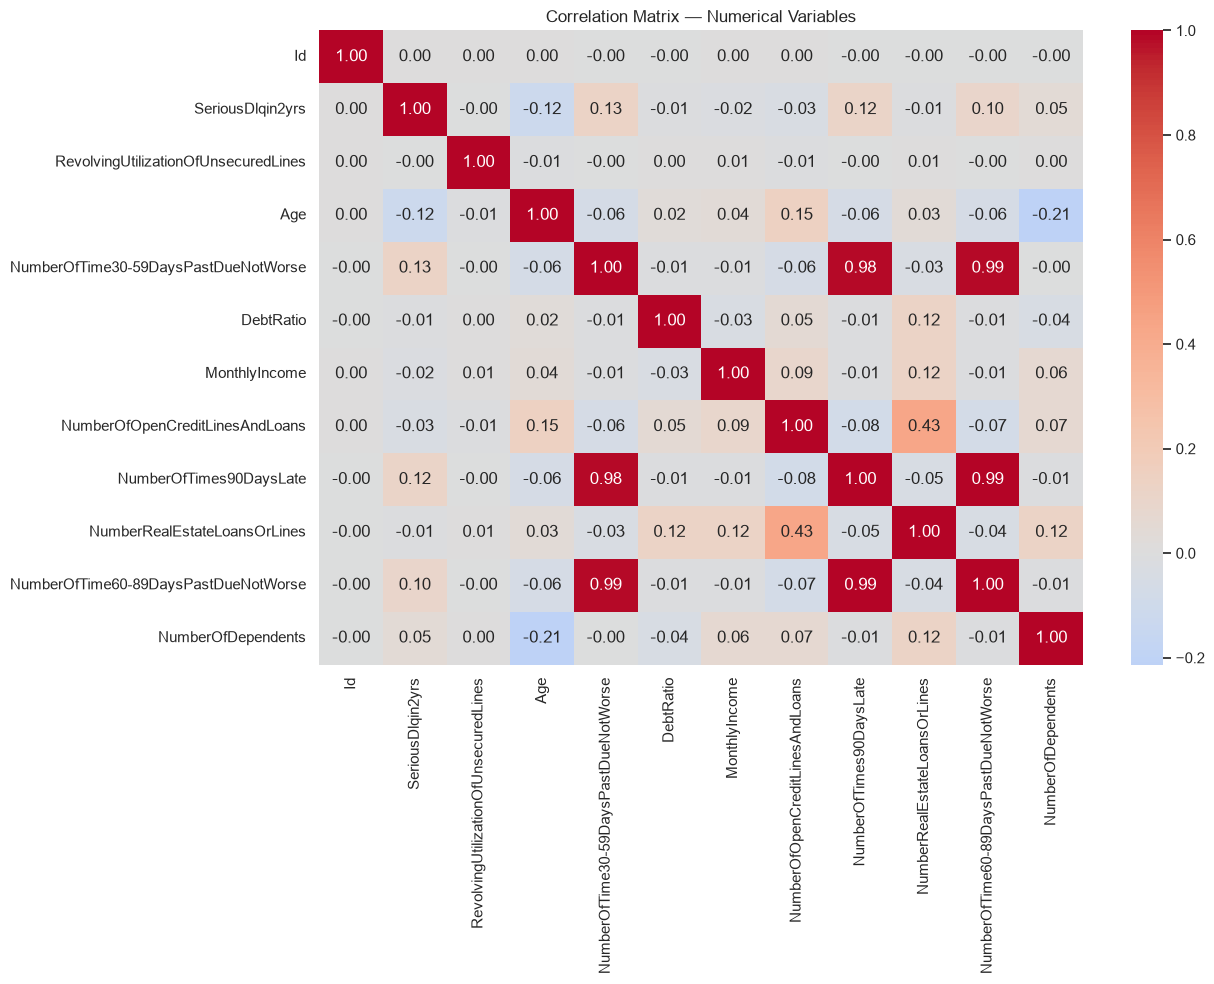

In [30]:
corr=df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(13,10))
sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Correlation Matrix — Numerical Variables")
plt.tight_layout()
plt.show()


In [31]:
display(corr["SeriousDlqin2yrs"].drop("SeriousDlqin2yrs").sort_values(key=abs,ascending=False).to_frame("Correlation with Target"))


,Correlation with Target
NumberOfTime30-59DaysPastDueNotWorse,0.126
NumberOfTimes90DaysLate,0.117
Age,-0.115
NumberOfTime60-89DaysPastDueNotWorse,0.102
NumberOfDependents,0.046
NumberOfOpenCreditLinesAndLoans,-0.030
MonthlyIncome,-0.020
DebtRatio,-0.008
NumberRealEstateLoansOrLines,-0.007
Id,0.003


## 15. Invalid / Suspicious Values

In [32]:
checks={
    "Age <= 0": int((df["Age"]<=0).sum()),
    "Age > 100": int((df["Age"]>100).sum()),
    "MonthlyIncome == 0": int((df["MonthlyIncome"]==0).sum()),
    "RevolvingUtilization > 1": int((df["RevolvingUtilizationOfUnsecuredLines"]>1).sum()),
    "DebtRatio > 1": int((df["DebtRatio"]>1).sum()),
    "Dependents > 10": int((df["NumberOfDependents"]>10).sum())
}
check_table=pd.DataFrame.from_dict(checks,orient="index",columns=["Count"])
check_table["Percentage"]=(check_table["Count"]/len(df)*100).round(3)
display(check_table)


,Count,Percentage
Age <= 0,1,0.001
Age > 100,13,0.009
MonthlyIncome == 0,1634,1.089
RevolvingUtilization > 1,3321,2.214
DebtRatio > 1,35137,23.425
Dependents > 10,2,0.001


## 16. Delinquency Value 98 Investigation

In [33]:
for col in delinq_cols:
    print("\n",col,"| value 98 count:",int((df[col]==98).sum()),"| max:",df[col].max())
    display(df[col].value_counts().sort_index().tail(20))



 NumberOfTime30-59DaysPastDueNotWorse | value 98 count: 264 | max: 98


NumberOfTime30-59DaysPastDueNotWorse
0     126018
1      16033
2       4598
3       1754
4        747
5        342
6        140
7         54
8         25
9         12
10         4
11         1
12         2
13         1
96         5
98       264
Name: count, dtype: int64


 NumberOfTimes90DaysLate | value 98 count: 264 | max: 98


NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
5        131
6         80
7         38
8         21
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
96         5
98       264
Name: count, dtype: int64


 NumberOfTime60-89DaysPastDueNotWorse | value 98 count: 264 | max: 98


NumberOfTime60-89DaysPastDueNotWorse
0     142396
1       5731
2       1118
3        318
4        105
5         34
6         16
7          9
8          2
9          1
11         1
96         5
98       264
Name: count, dtype: int64

## 17. IQR Outlier Summary

In [34]:
rows=[]
for col in numeric_predictors:
    s=df[col].dropna()
    q1=s.quantile(.25)
    q3=s.quantile(.75)
    iqr=q3-q1
    lo=q1-1.5*iqr
    hi=q3+1.5*iqr
    count=int(((df[col]<lo)|(df[col]>hi)).sum())
    rows.append([col,q1,q3,iqr,lo,hi,count,round(count/len(df)*100,2)])

outliers=pd.DataFrame(rows,columns=[
    "Variable","Q1","Q3","IQR","Lower Bound","Upper Bound","IQR Outliers","Outlier %"
])
display(outliers.sort_values("IQR Outliers",ascending=False))


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,IQR Outliers,Outlier %
3,DebtRatio,0.175,0.868,0.693,-0.865,1.908,31311,20.870
2,NumberOfTime30-59DaysPastDueNotWorse,0.000,0.000,0.000,0.000,0.000,23982,15.990
9,NumberOfDependents,0.000,1.000,1.000,-1.500,2.500,13336,8.890
6,NumberOfTimes90DaysLate,0.000,0.000,0.000,0.000,0.000,8338,5.560
8,NumberOfTime60-89DaysPastDueNotWorse,0.000,0.000,0.000,0.000,0.000,7604,5.070
4,MonthlyIncome,"3,400.000","8,249.000","4,849.000","-3,873.500","15,522.500",4879,3.250
5,NumberOfOpenCreditLinesAndLoans,5.000,11.000,6.000,-4.000,20.000,3980,2.650
7,NumberRealEstateLoansOrLines,0.000,2.000,2.000,-3.000,5.000,793,0.530
0,RevolvingUtilizationOfUnsecuredLines,0.030,0.559,0.529,-0.764,1.353,763,0.510
1,Age,41.000,63.000,22.000,8.000,96.000,46,0.030


## 18. Data Cleaning Strategy

The original `df` is preserved and a separate `df_clean` is created.

- Remove exact duplicate rows.
- Treat `Age <= 0` as invalid and set it to missing.
- If `Gender` is more than 95% missing, remove it instead of mode-imputing almost the entire column.
- Median-impute `MonthlyIncome`, `NumberOfDependents`, and corrected `Age`.
- Do not automatically delete high `DebtRatio` or utilization values.
- Do not automatically change delinquency value `98`; verify its meaning against the Data Dictionary first.


In [35]:
df_clean=df.copy()
df_clean=df_clean.drop_duplicates().copy()

df_clean.loc[df_clean["Age"]<=0,"Age"]=np.nan

if df_clean["Gender"].isna().mean()>.95:
    df_clean=df_clean.drop(columns=["Gender"])

for col in ["MonthlyIncome","NumberOfDependents","Age"]:
    if col in df_clean.columns:
        df_clean[col]=df_clean[col].fillna(df_clean[col].median())

print("Cleaning completed.")


Cleaning completed.


## 19. Original vs Cleaned Dataset

In [36]:
comparison=pd.DataFrame({
    "Dataset":["Original","Cleaned"],
    "Rows":[df.shape[0],df_clean.shape[0]],
    "Columns":[df.shape[1],df_clean.shape[1]]
})
display(comparison)

missing_compare=pd.DataFrame({
    "Original Missing":df.isna().sum(),
    "Cleaned Missing":df_clean.isna().sum()
})
display(missing_compare)


,Dataset,Rows,Columns
0,Original,150000,13
1,Cleaned,150000,12


,Original Missing,Cleaned Missing
Age,0,0.000
DebtRatio,0,0.000
Gender,149693,NaN
Id,0,0.000
MonthlyIncome,29731,0.000
NumberOfDependents,3924,0.000
NumberOfOpenCreditLinesAndLoans,0,0.000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000
NumberOfTime60-89DaysPastDueNotWorse,0,0.000
NumberOfTimes90DaysLate,0,0.000


## 20. Cleaned Dataset Preview

In [37]:
display(df_clean.head())
df_clean.info()


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766,45.000,2,0.803,"9,120.000",13,0,6,0,2.000
1,2,0,0.957,40.000,0,0.122,"2,600.000",4,0,0,0,1.000
2,3,0,0.658,38.000,1,0.085,"3,042.000",2,1,0,0,0.000
3,4,0,0.234,30.000,0,0.036,"3,300.000",5,0,0,0,0.000
4,5,0,0.907,49.000,1,0.025,"63,588.000",7,0,1,0,0.000


<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Id                                    150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   Age                                   150000 non-null  float64
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         150000 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

## 21. Before vs After Target Distribution

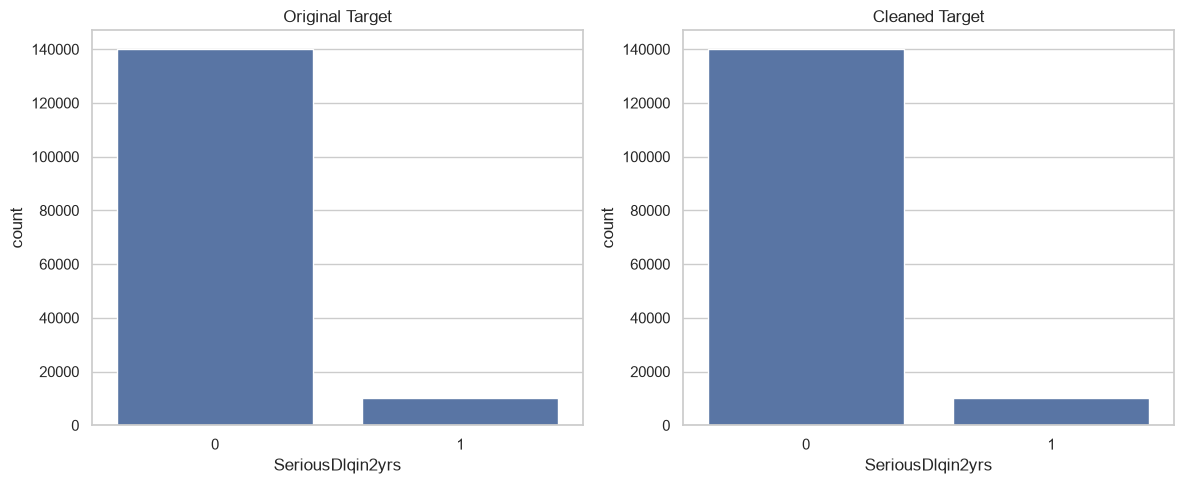

In [38]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.countplot(data=df,x="SeriousDlqin2yrs",ax=axes[0])
axes[0].set_title("Original Target")
sns.countplot(data=df_clean,x="SeriousDlqin2yrs",ax=axes[1])
axes[1].set_title("Cleaned Target")
plt.tight_layout()
plt.show()


## 22. Final Findings

Use the computed tables and graphs above in the report. Discuss:
1. Target class balance.
2. Extremely high missingness in `Gender`.
3. Missing values in `MonthlyIncome` and `NumberOfDependents`.
4. Invalid/suspicious age values.
5. Extreme `DebtRatio` and revolving-utilization observations.
6. The value `98` in delinquency fields and the need to verify its meaning from the Data Dictionary.
7. Important associations shown by target-rate and correlation analyses.

Correlation indicates association, not causation.


## 23. Export Cleaned Dataset

In [39]:
# Uncomment this line if you want to create the cleaned CSV:
# df_clean.to_csv("CreditScore_cleaned.csv", index=False)

print("Complete EDA notebook finished.")


Complete EDA notebook finished.
